## MedImageParse: A Unified Model for Biomedical Image Analysis

## Prerequisites

This notebook requires the following setup. If you haven't completed these steps, please refer to the Getting Started section in the main README, which includes:

1. Deploying required models
2. Installing the Healthcare AI Toolkit
3. Downloading sample data
4. Configuring your `.env` file

### Required for This Notebook

- **Model Endpoint(s)**: `MIP_MODEL_ENDPOINT`
## Introduction

Biomedical image analysis plays a critical role in advancing scientific discoveries across multiple fields, such as **cell biology, pathology, radiology**, and more. However, extracting meaningful insights from medical images presents challenges, especially in tasks such as:

- **Segmentation:** Precisely outlining organs, abnormalities, and cells.
- **Detection:** Identifying specific structures like tumors or anomalies.
- **Recognition:** Assigning semantic labels to detected objects for further analysis.

Traditionally, these tasks were treated separately. **MedImageParse** (formerly known as BiomedParse) changes this by unifying segmentation, detection, and recognition into a single model. This unlocks new opportunities for clinicians and researchers, enabling them to focus more on discovery and insights rather than technical complexities.

**MedImageParse** is a biomedical foundation model developed in collaboration with **Microsoft Research, Providence Genomics**, and the **Paul G. Allen School of Computer Science and Engineering** at the University of Washington. It is part of the **Microsoft healthcare AI models** initiative.



## 1. Setup and Imports

In [ ]:
from healthcareai_toolkit.clients import get_medimage_client
from healthcareai_toolkit import settings

client = get_medimage_client("mip")

Using ml_client base_url 1: https://management.azure.com
Using ml_client base_url 2: https://management.azure.com


In [ ]:
import os

data_root = settings.DATA_ROOT
example_dir = os.path.join(data_root, "segmentation-examples")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from healthcareai_toolkit.data.io import read_nifti_2d
from healthcareai_toolkit.data.manip import extract_instance_masks


def show_image_with_mask(
    image: np.ndarray,
    mask: np.ndarray,
    alpha: float = 0.5,
    title=None,
    ax: plt.Axes = None,
    colormap: str = "Set1",
):
    if image.shape[:2] != mask.shape:
        raise ValueError(
            "The dimensions of the mask do not match the dimensions of the image."
        )

    labels = np.unique(mask)
    labels = labels[labels > 0]  # Exclude background
    cmap = plt.get_cmap(colormap)
    norm = plt.Normalize(vmin=labels.min(), vmax=labels.max())

    overlay = np.zeros((*mask.shape, 4), dtype=np.float32)
    for label in labels:
        color = cmap(norm(label))[:3]  # Get RGB values
        overlay[mask == label] = [*color, alpha]

    show = False
    if ax is None:
        ax = plt.gca()
        show = True

    ax.imshow(image)
    ax.imshow(overlay)
    ax.axis("off")
    if title is not None:
        ax.set_title(title)
    if show:
        plt.show()


def visualize_segmentation_results(
    image, results, prompt=None, extract_instance=False, colormap: str = "Set1"
):
    text_features = results[0]["text_features"]
    masks = results[0]["image_features"]
    masks = (masks > 0).astype("uint8")

    print("Image shape:", image.shape)
    print("Segmentation Mask shape: ", masks.shape)
    print("Text features: ", text_features)

    if extract_instance:
        masks = [extract_instance_masks(mask) for mask in masks]

    fig, axes = plt.subplots(1, len(masks), figsize=(40, 10 * len(masks)))
    if len(masks) == 1:
        axes = [axes]
    for ax, mask, mask_name in zip(axes, masks, text_features):
        show_image_with_mask(image, mask, title=mask_name, ax=ax, colormap=colormap)

## 2. Segmentation Examples
Below are several examples illustrating MedImageParse's prompt-based approach to segmentation. These examples demonstrate its capability to accurately segment various biomedical structures across different imaging modalities.


### 2.1 Lung Nodule Segmentation from Radiological Chest CT DICOM 
This example demonstrates a prompt to create a single segmentation mask from a single CT slice. Note that we configure our image pre-processing code to apply "lung" window to the image before sending it to the model, for better localization. Note that the model effectively performs detection task alongside a segmentation task.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (1, 1024, 1024)
Text features:  ['other lesion']


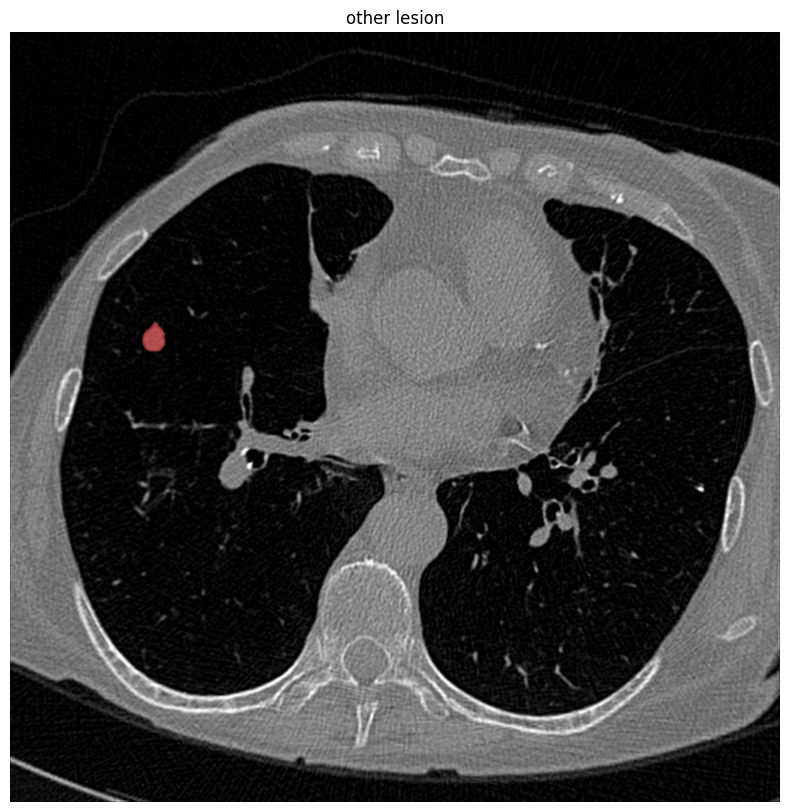

In [ ]:
image_path = os.path.join(example_dir, "CT_lung_nodule.dcm")
text_prompt = "nodule"

image = client.read_and_normalize_image(image_path, special_overrides="ct-lung")
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.2 Neuroradiological Analysis of Tumor Core, Enhancing, and Non-Enhancing Tumors using MRI T1-Gad

This example demonstrates multiple prompts to segment parts of a glioblastoma, an aggressive form brain cancer from a brain MR scan obtained using a contrast injection technique to highlight active tumor and provide better differentiation of tissues. Note that we show a technique to parse a NIFTI file and extract a slice from before preparing an image to send to the MedImageParse model. The model returns three segmentation masks and we demonstrate a technique to parse and display them.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


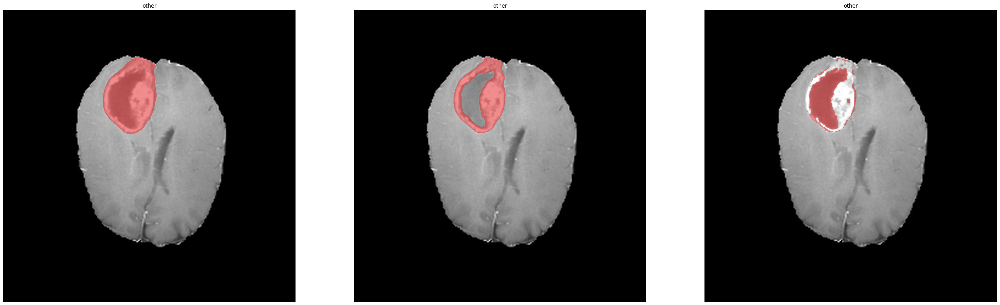

In [ ]:
image_path = os.path.join(example_dir, "BRATS_397.nii.gz")
text_prompt = "tumor core & enhancing tumor & non-enhancing tumor"
image = read_nifti_2d(image_path, slice_idx=89, HW_index=(1, 0), channel_idx=2)
image = client.read_and_normalize_image(image)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.3 Neuroradiological Analysis of Whole Tumor, Tumor Core, and Edema using MRI-FLAIR

This is an example similar to the previous one where we are asking the model to segment parts of a brain tumor on a different type of MRI scan called FLAIR (Fluid-Attenuated Inversion Recovery) which is a fluid-sensitive technique that can improve visibility of lesions alongside edema.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


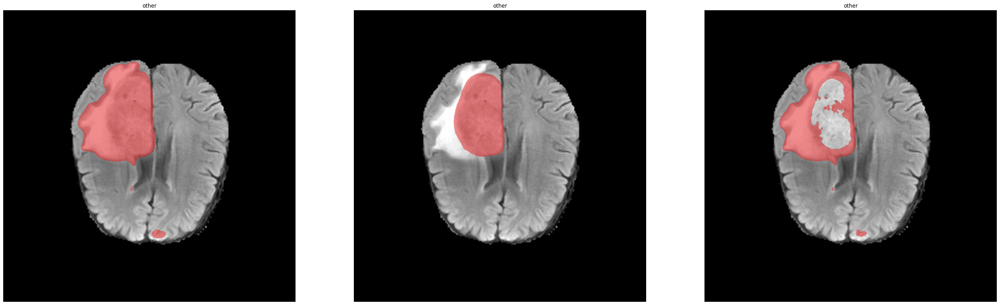

In [ ]:
image_path = os.path.join(example_dir, "BRATS_422.nii.gz")
text_prompt = "whole tumor & tumor core & edema"
image = read_nifti_2d(image_path, slice_idx=84, HW_index=(1, 0), channel_idx=0)
image = client.read_and_normalize_image(image)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.4 Radiological Analysis of Kidney, Tumor, and Cyst using CT Imaging

This is another example that involves parsing a slice from a NIFTI file that contains an entire CT volume. In this example we are segmenting renal anatomy as well as both simple cysts (right side of image, left kidney) and renal malignancies (left side of image, right kidney).

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


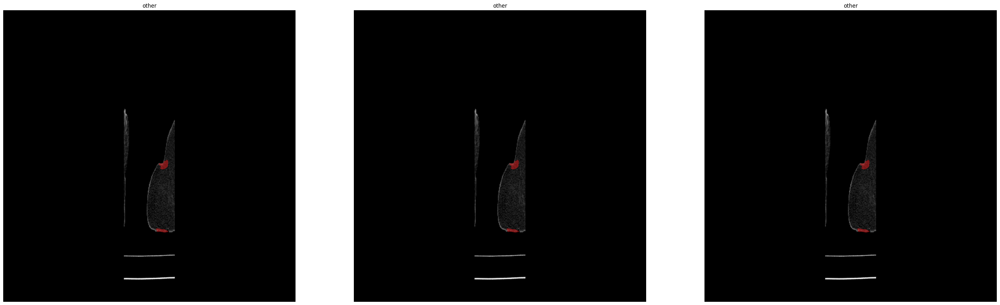

In [ ]:
image_path = os.path.join(example_dir, "CT_kidney.nii.gz")
text_prompt = "kidney & tumor & cyst"

image = read_nifti_2d(image_path, slice_idx=32, HW_index=(1, 0), channel_idx=None)
# You need this outside of the loop since MIP requires special re-shaping
image = client.read_and_normalize_image(image, special_overrides="ct-abdomen")
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.5 Echocardiographic Analysis of Left Ventricle and Left Atrium using Ultrasound Imaging

This example showcases the segmentation of a single frame from a sequence obtained using a different imaging modality - ultrasound. This type of imaging study is called an echocardiogram and it is used for study of cardiac function. In this example we are segmenting ventricular and atrial volumes from a transthoracic echocardiogram.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (2, 1024, 1024)
Text features:  ['other', 'other']


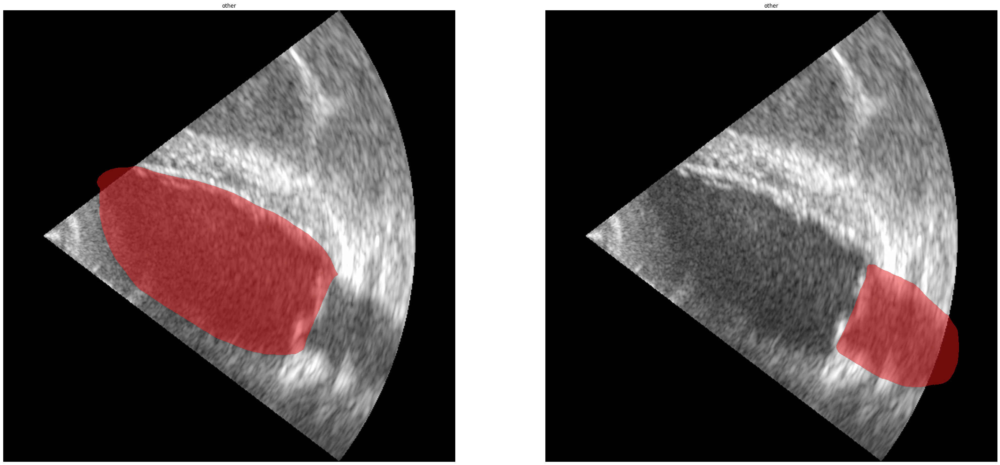

In [ ]:
image_path = os.path.join(example_dir, "patient0500_2CH_half_sequence.nii.gz")
text_prompt = "left ventricle & left atrium"

image = read_nifti_2d(image_path, slice_idx=0, HW_index=(0, 1), channel_idx=None)
image = client.read_and_normalize_image(image)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.6 Histopathological Analysis and Cell Phenotyping of Neoplastic, Inflammatory, and Connective Tissue Cells

In this example we are submitting a single image representing a portion of a digital pathology H&E slide.

Image shape: (1024, 1024, 4)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


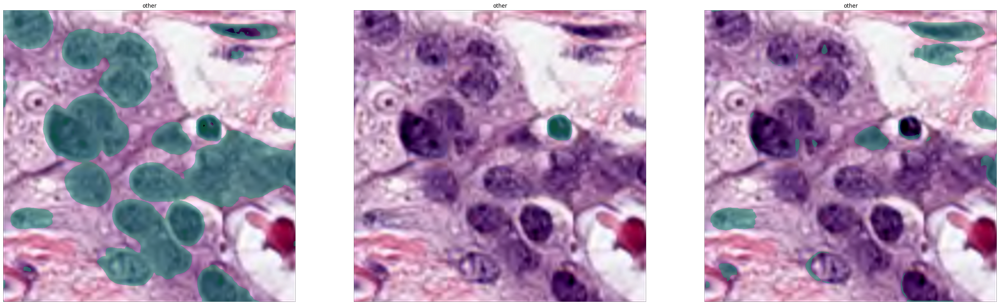

In [ ]:
image_path = os.path.join(example_dir, "pathology_breast_1.png")
text_prompt = "neoplastic cells & inflammatory cells & connective tissue cells"

image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results, colormap="Dark2")

### 2.7 Perform Single Cell Analysis
The example below shows how to process MedImageParse output to visualize individual cells by appearance and classification using the output from the previous query.

Image shape: (1024, 1024, 4)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


MaskImageFilter (0x7ffcdd3d9880): Support for pixel type 32-bit unsigned integer for the MaskImage input has been deprecated and will be removed in future versions. Implicitly casting input to support 'sitkUInt8' type. MaskImageFilter (0x7ffcdd3d9880): Support for pixel type 32-bit unsigned integer for the MaskImage input has been deprecated and will be removed in future versions. Implicitly casting input to support 'sitkUInt8' type. MaskImageFilter (0x7ffcdd3d9880): Support for pixel type 32-bit unsigned integer for the MaskImage input has been deprecated and will be removed in future versions. Implicitly casting input to support 'sitkUInt8' type. 

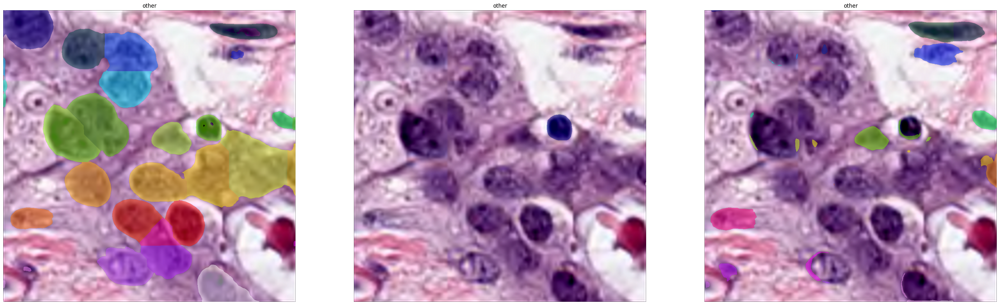

In [ ]:
visualize_segmentation_results(
    image, results, extract_instance=True, colormap="gist_ncar"
)

### 2.8 Radiological Analysis of Left Lung, Right Lung, and COVID-19 Infection

The following example shows how the model can leverage its training data that contained a dataset of COVID patients to segment lung pathologies typical of a COVID infection

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (3, 1024, 1024)
Text features:  ['other', 'other', 'other']


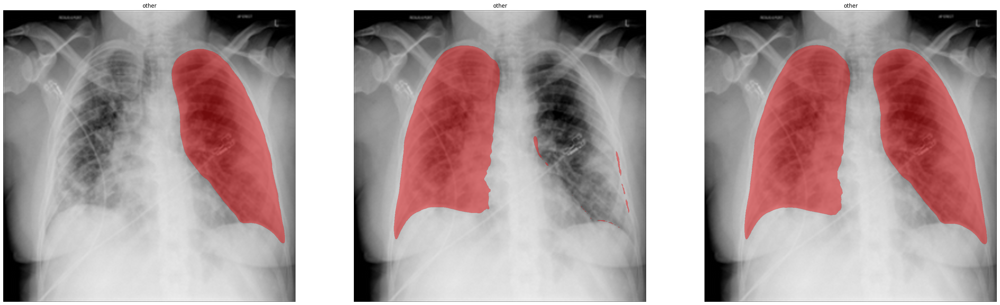

In [ ]:
image_path = os.path.join(example_dir, "covid_1585.png")
text_prompt = "left lung & right lung & COVID-19 infection"

image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.9 Ophthalmological Analysis of Optic Disc and Optic Cup

The image below is a photograph of a retina obtained using fundus camera. MedImageParse successfully segments portions of the anatomy in the image.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (2, 1024, 1024)
Text features:  ['other', 'eye anatomies']


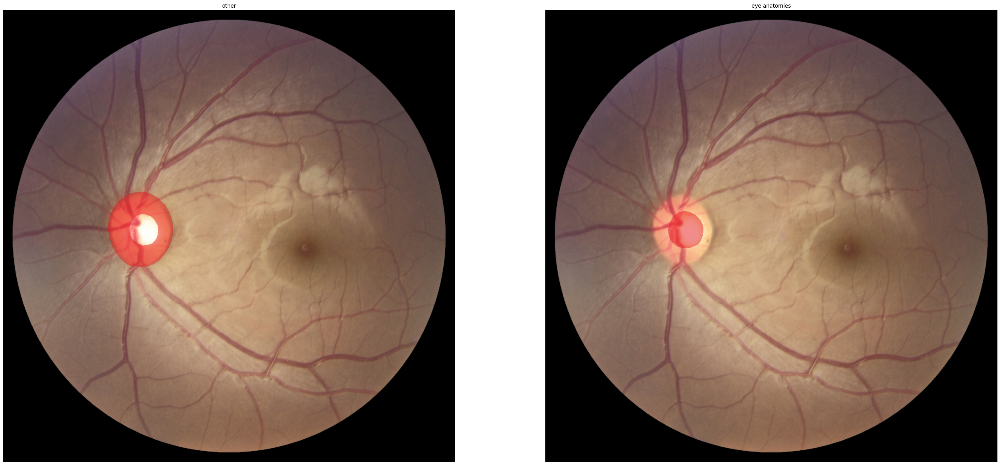

In [ ]:
image_path = os.path.join(example_dir, "T0011.jpg")
text_prompt = "optic disc & optic cup"
image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.10 Endoscopic Analysis of Polyp

The image below is a frame from colonoscopy video with a large colon polyp.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (1, 1024, 1024)
Text features:  ['other lesion']


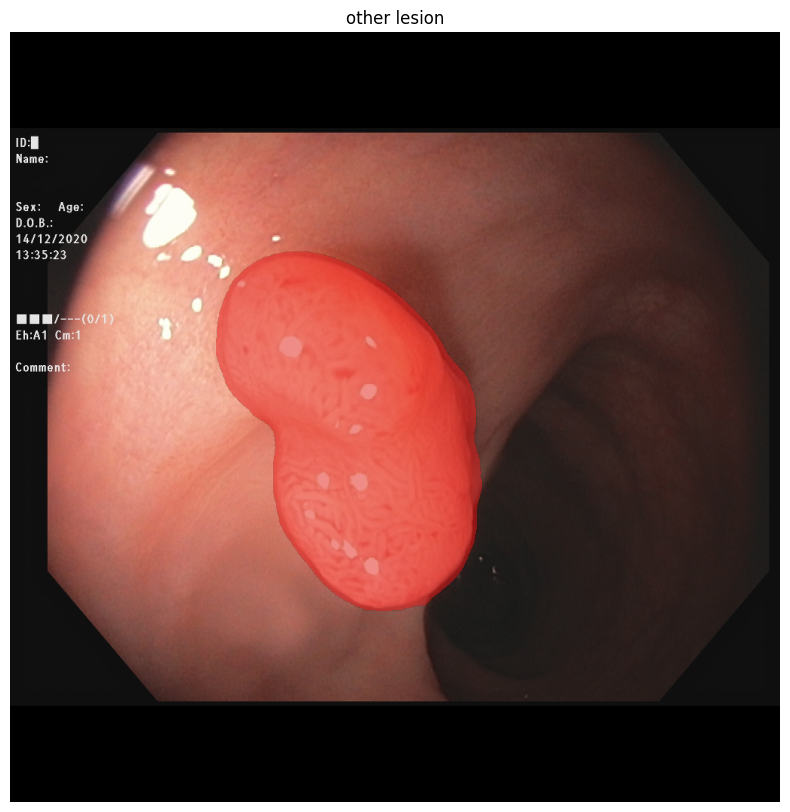

In [ ]:
image_path = os.path.join(example_dir, "C3_EndoCV2021_00462.jpg")
text_prompt = "polyp"
image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.11 Dermatological Analysis of Skin Lesion

The image used in the following example is a high-resolution dermoscopic image that is resized to send it to MedImageParse model.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (1, 1024, 1024)
Text features:  ['other lesion']


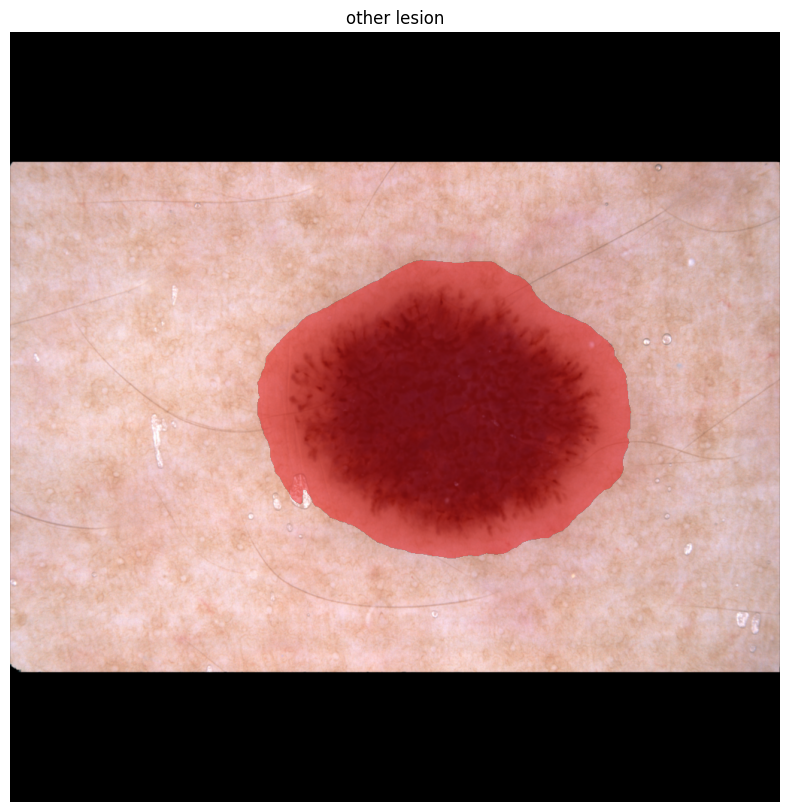

In [ ]:
image_path = os.path.join(example_dir, "ISIC_0015551.jpg")
text_prompt = "skin lesion"
image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

### 2.12 Ophthalmological Analysis of Edema using OCT

The following image is a slice from an OCT scan, a type of eye exam used to evaluate the health of the retina. Note how MedImageParse is able to identify and segment a pathology in the scan.

Image shape: (1024, 1024, 3)
Segmentation Mask shape:  (1, 1024, 1024)
Text features:  ['fluid disturbance']


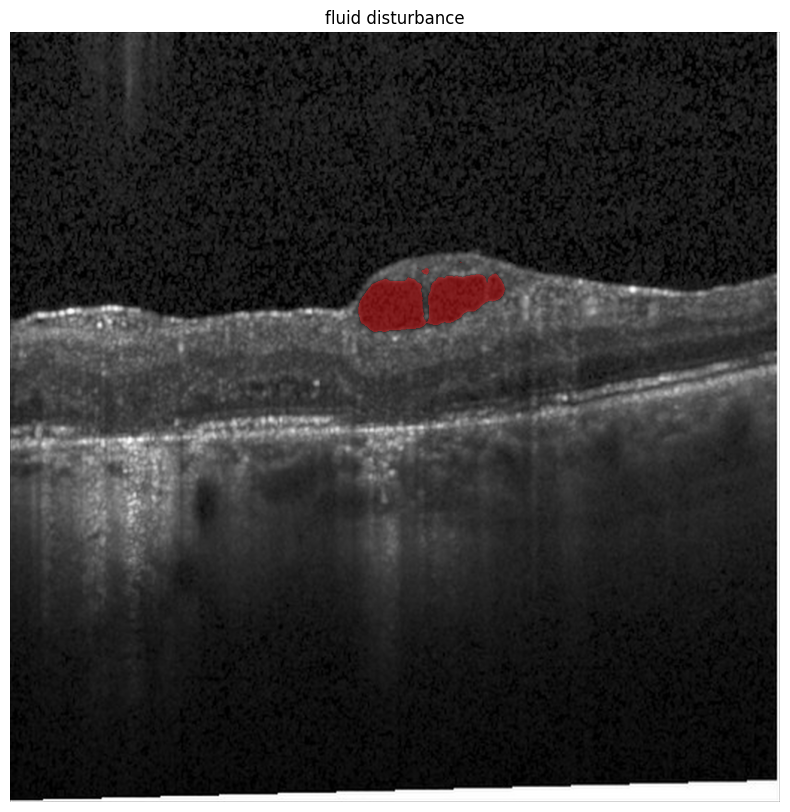

In [ ]:
image_path = os.path.join(example_dir, "144DME_as_F.jpeg")
text_prompt = "edema"
image = client.read_and_normalize_image(image_path)
results = client.submit(image_list=[image], prompts=[text_prompt])

visualize_segmentation_results(image, results)

# 4. References

For further details see:

 - [BiomedParse OSS Github project](https://microsoft.github.io/BiomedParse/)

 - [BiomedParse Paper](https://arxiv.org/abs/2405.12971)